In [5]:
import numpy as np
import pandas as pd 

data=pd.read_excel("XPON_QUALIF(1).xlsx")
data.head()

,ID_LIGNE,ID_CARTE_OLT,NO_PORT,ONU_ID,F_SUSP,ADMIN_STATUS,OPER_STATUS,OLT_POWER_TX,OLT_RX_ONT_POWER,ONU_POWER_TX,ONU_POWER_RX,DESGOUV
0,80190644,63,1,6,0,0,0,NaN,NaN,NaN,NaN,SOUSSE
1,80210544,63,1,6,0,0,0,NaN,NaN,NaN,NaN,SOUSSE
2,80269544,63,1,6,0,0,0,NaN,NaN,NaN,NaN,SOUSSE
3,80290544,63,1,6,0,0,0,NaN,NaN,NaN,NaN,SOUSSE
4,80290944,63,1,6,0,0,0,NaN,NaN,NaN,NaN,SOUSSE


In [2]:
data.dropna(inplace=True)



In [3]:
data = data.drop_duplicates()

In [4]:
def etat_valeur(v, low, high):
    if v < low:
        return 1
    elif v <= high:
        return 0
    else:
        return 1
data["Etat_OLT_TX"] = data["OLT_POWER_TX"].apply(lambda x: etat_valeur(x, 2, 7))
data["Etat_OLT_RX"] = data["OLT_RX_ONT_POWER"].apply(lambda x: etat_valeur(x, -32, -12))
data["Etat_ONU_TX"] = data["ONU_POWER_TX"].apply(lambda x: etat_valeur(x, 2, 5))
data["Etat_ONU_RX"] = data["ONU_POWER_RX"].apply(lambda x: etat_valeur(x, -28, -7))


In [5]:
def etat_global(row):
    if 1 in row.values:
        return 1
    return 0

data["Anomalie_technique"] = data[
    ["Etat_OLT_TX","Etat_OLT_RX","Etat_ONU_TX","Etat_ONU_RX"]
].apply(etat_global, axis=1)


In [6]:
# Anomalie admin = ligne suspendue (F_SUSP=1) 
# OU port désactivé sans suspension (ADMIN_STATUS=0 sans raison)
# OU ligne suspendue mais encore online (F_SUSP=1 et OPER_STATUS=1)

data["Anomalie_admin"] = np.where(
    (data["F_SUSP"] == 1) |                                      # ligne suspendue
    ((data["ADMIN_STATUS"] == 0) & (data["OPER_STATUS"] == 1)) | # port OFF mais online
    ((data["F_SUSP"] == 1) & (data["OPER_STATUS"] == 1)),        # suspendu mais encore online
    1, 0
)

print("Anomalie_admin distribution:")
print(data["Anomalie_admin"].value_counts())
print(f"\nDétail des cas :")
print(f"  F_SUSP=1                          : {(data['F_SUSP']==1).sum()}")
print(f"  ADMIN=0 et OPER=1 (incohérence)   : {((data['ADMIN_STATUS']==0) & (data['OPER_STATUS']==1)).sum()}")
print(f"  F_SUSP=1 et OPER=1 (encore online): {((data['F_SUSP']==1) & (data['OPER_STATUS']==1)).sum()}")

Anomalie_admin distribution:
Anomalie_admin
0    6663
1      29
Name: count, dtype: int64

Détail des cas :
  F_SUSP=1                          : 6
  ADMIN=0 et OPER=1 (incohérence)   : 23
  F_SUSP=1 et OPER=1 (encore online): 6


In [7]:
data["Anomalie"] = np.where(
    (data["Anomalie_technique"] == 1) | (data["Anomalie_admin"] == 1),
    1,
    0
)

print("Anomalie distribution:")
print(data["Anomalie"].value_counts())
print(f"\nDétail :")
print(f"  Anomalie technique seulement : {((data['Anomalie_technique']==1) & (data['Anomalie_admin']==0)).sum()}")
print(f"  Anomalie admin seulement     : {((data['Anomalie_technique']==0) & (data['Anomalie_admin']==1)).sum()}")
print(f"  Les deux en même temps       : {((data['Anomalie_technique']==1) & (data['Anomalie_admin']==1)).sum()}")
print(f"  Total anomalies              : {(data['Anomalie']==1).sum()}")

Anomalie distribution:
Anomalie
0    6046
1     646
Name: count, dtype: int64

Détail :
  Anomalie technique seulement : 617
  Anomalie admin seulement     : 29
  Les deux en même temps       : 0
  Total anomalies              : 646


In [10]:
nulls = pd.DataFrame({
    "Nombre_NULL": data.isnull().sum(),
    "Pourcentage_%": (data.isnull().sum() / len(data)) * 100
})

nulls

,Nombre_NULL,Pourcentage_%
ID_LIGNE,0,0.0
ID_CARTE_OLT,0,0.0
NO_PORT,0,0.0
ONU_ID,0,0.0
F_SUSP,0,0.0
ADMIN_STATUS,0,0.0
OPER_STATUS,0,0.0
OLT_POWER_TX,0,0.0
OLT_RX_ONT_POWER,0,0.0
ONU_POWER_TX,0,0.0


In [6]:
# Vérifier les doublons (toutes colonnes)
doublons = data.duplicated()

# Compter le nombre de doublons
print("Nombre de doublons :", doublons.sum())

# Afficher les lignes dupliquées
print(data[doublons])

Nombre de doublons : 77
     ID_LIGNE  ID_CARTE_OLT  NO_PORT  ONU_ID  F_SUSP  ADMIN_STATUS  \
34   83109506           101       10       1       0             1   
35   83109506           101       10       1       0             1   
36   83109506           101       10       1       0             1   
37   83109506           101       10       1       0             1   
38   83109506           101       10       1       0             1   
..        ...           ...      ...     ...     ...           ...   
305  85414086           111        7       7       0             1   
306  85414086           111        7       7       0             1   
307  85414086           111        7       7       0             1   
308  85414086           111        7       7       0             1   
309  85414086           111        7       7       0             1   

     OPER_STATUS  OLT_POWER_TX  OLT_RX_ONT_POWER  ONU_POWER_TX ONU_POWER_RX  \
34             1           3.6             -25.6        

In [15]:

colonnes_a_cacher = ["Etat_OLT_TX", "Etat_OLT_RX", "Etat_ONU_RX","Anomalie_technique","Anomalie_admin","Anomalie","Etat_ONU_TX"]
data.drop(columns=colonnes_a_cacher).info()

<class 'pandas.core.frame.DataFrame'>
Index: 6692 entries, 6 to 9001
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID_LIGNE          6692 non-null   int64  
 1   ID_CARTE_OLT      6692 non-null   int64  
 2   NO_PORT           6692 non-null   int64  
 3   ONU_ID            6692 non-null   int64  
 4   F_SUSP            6692 non-null   int64  
 5   ADMIN_STATUS      6692 non-null   int64  
 6   OPER_STATUS       6692 non-null   int64  
 7   OLT_POWER_TX      6692 non-null   float64
 8   OLT_RX_ONT_POWER  6692 non-null   float64
 9   ONU_POWER_TX      6692 non-null   float64
 10  ONU_POWER_RX      6692 non-null   object 
 11  DESGOUV           6692 non-null   object 
dtypes: float64(3), int64(7), object(2)
memory usage: 679.7+ KB


In [ ]:
print(len(data))

6692


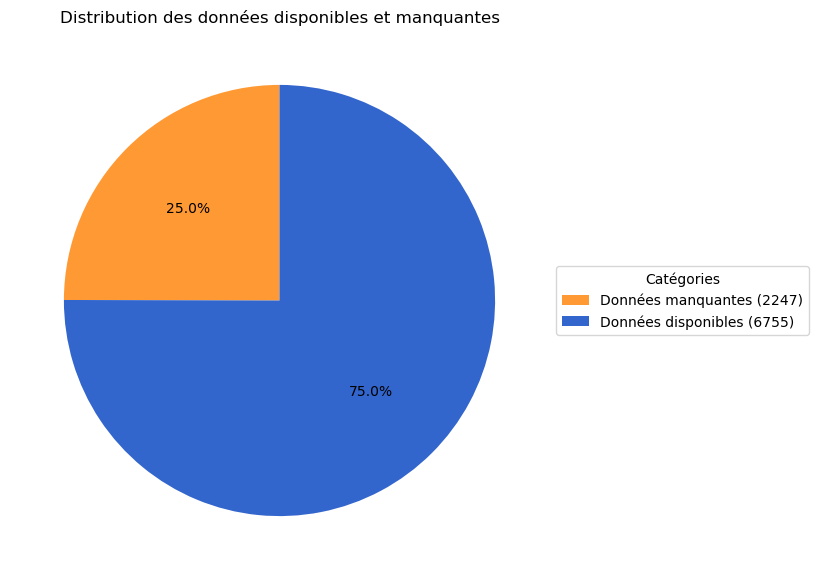

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


# Compter les lignes avec au moins une valeur manquante
rows_with_missing = data.isnull().any(axis=1).sum()
rows_without_missing = len(data) - rows_with_missing

# Préparer les données
sizes = [rows_with_missing, rows_without_missing]
labels = [
    f"Données manquantes ({rows_with_missing})",
    f"Données disponibles ({rows_without_missing})"
]
colors = ['#ff9933', '#3366cc']

# Tracer le pie chart
plt.figure(figsize=(7,7))
wedges, texts, autotexts = plt.pie(
    sizes,
    colors=colors,
    autopct='%1.1f%%',
    startangle=90
)

# Ajouter la légende
plt.legend(
    wedges,
    labels,
    title="Catégories",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1)
)

plt.title("Distribution des données disponibles et manquantes")
plt.show()
